# Perceptrón Multicapa - MLP  

## Fundamentos

Un **Perceptrón Multicapa (MLP)** es una red neuronal artificial *feedforward* compuesta por al menos tres capas de nodos:
1. **Capa de Entrada (Input Layer):** Recibe las características (*features*) del dataset.
2. **Capas Ocultas (Hidden Layers):** Capas intermedias que transforman las entradas mediante combinaciones lineales (Z=WTX+b) y funciones de activación no lineales ($\phi(Z)$).
3. **Capa de Salida (Output Layer):** Genera la predicción o clasificación final.

## Modelo Matemático

$$\hat{y} = \phi \left( \sum_{i=1}^{n} w_i x_i + b \right) = \phi (W^T X + b)$$

- X: Representa el vector de características de entrada a evaluar.   
- W: Representa la matriz de pesos que determinan la importancia de cada entrada.   
- b: Es el sesgo (bias) que permite desplazar la función de activación.   
- $\phi$: Representa la función de activación que introduce la no-linealidad (como ReLU o Sigmoide).
- **Backpropagation:** Algoritmo que calcula el gradiente del error respecto a cada peso y sesgo para ajustarlos mediante Descenso de Gradiente.


### Función de Activación (Relu)

$$R(z) = \max(0, z)$$
- Si la entrada es negativa (\(z < 0\)): La función devuelve 0. La neurona se "apaga" y bloquea el paso de la señal
- Si la entrada es positiva (\(z \ge 0\)): La función devuelve el valor exacto que recibió. La neurona se "activa" de forma lineal y proporcional a la fuerza de la señal.

### Función de activación (Softmax)

![funcion](https://miro.medium.com/v2/resize:fit:640/format:webp/1*HSVJDdOh08MH53sngkqJeQ.png
)

Donde:
- $(z_i)$: valor de entrada de la neurona $(i)$, antes de aplicar Softmax.
- $(e)$: número de Euler, una constante matemática aproximadamente igual a 2.71828.
- $(e^{z_i})$: exponencial del valor correspondiente a la neurona $(i)$.
- $(\sum)$: símbolo de sumatoria, indica que debemos sumar varios valores.
- $(j)$: índice que recorre todas las neuronas de salida.
- $(K)$: número total de clases que queremos clasificar. En Iris, $(K=3)$.
- $({Softmax}(z_i))$: probabilidad asignada a la clase $(i)$.

### Función de pérdida (Entropía Cruzada Categórica)

Mide la diferencia entre la clase real y las probabilidades predichas por el modelo para cada una de las clases.

$$J(W, b) = -\frac{1}{N} \sum_{i=1}^{N} \sum_{c=1}^{M} y_{i,c} \log(\hat{y}_{i,c})$$

Donde los componentes representan lo siguiente:
- $J(W, b)$: El valor total de la pérdida (o costo) de la red, el cual el optimizador busca minimizar ajustando los pesos ($W$) y sesgos ($b$).
- $N$: El número total de patrones o muestras en el conjunto de entrenamiento.
- $M$: El número de clases posibles (3 en el caso de las especies de la flor Iris).

- $y_{i,c}$: Un indicador binario (1 o 0) de la etiqueta real que señala si la clase $c$ es la respuesta correcta para la muestra $i$.
- $\hat{y}_{i,c}$: La probabilidad predicha por la red neuronal (en la capa de salida) de que la muestra $i$ pertenezca a la clase $c$.

## Descripción de librerías, clases, funciones y parámetros

- **pandas (pd)**: carga y manipulación del dataset (read_csv, DataFrame).
- **numpy (np)**: operaciones numéricas.
- **matplotlib.pyplot (plt) y seaborn (sns)**: visualización (histogramas, dispersión, curvas).
- **sklearn.datasets.load_iris**: dataset Iris (clásico para clasificación).
- **sklearn.model_selection.train_test_split**: separar datos de entrenamiento y prueba.
- StandardScaler: escala variables.
- train_test_split: Función que divide aleatoriamente el conjunto de datos completo en una matriz de entrenamiento y otra de evaluación.
- **confusion_matrix, accuracy_score, classification_report**: métricas (matriz de confusión, accuracy, precision/recall/F1).

# Pipeline

Primero se importan las librerías, se construye un DataFrame y se verifican tamaño, clases y valores ausentes.

In [1]:
# Importar las librerías para el análisis, visualización y modelado.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay


# Cargamos el dataset Iris que viene incluido en scikit-learn.
iris = load_iris()

# Convertimos las cuatro medidas a una tabla con nombres de columnas.
df = pd.DataFrame(iris.data, columns=iris.feature_names)

# Guardamos las etiquetas como números enteros (0, 1, 2).
df["species_id"] = iris.target

# Añadimos los nombres de las especies para facilitar su interpretación.
df["species"] = [iris.target_names[i] for i in iris.target]

# Mostramos una muestra de la información disponible.
display(df.head())

print("Clases:", dict(zip(range(3), iris.target_names)))



,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species_id,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


Clases: {0: np.str_('setosa'), 1: np.str_('versicolor'), 2: np.str_('virginica')}


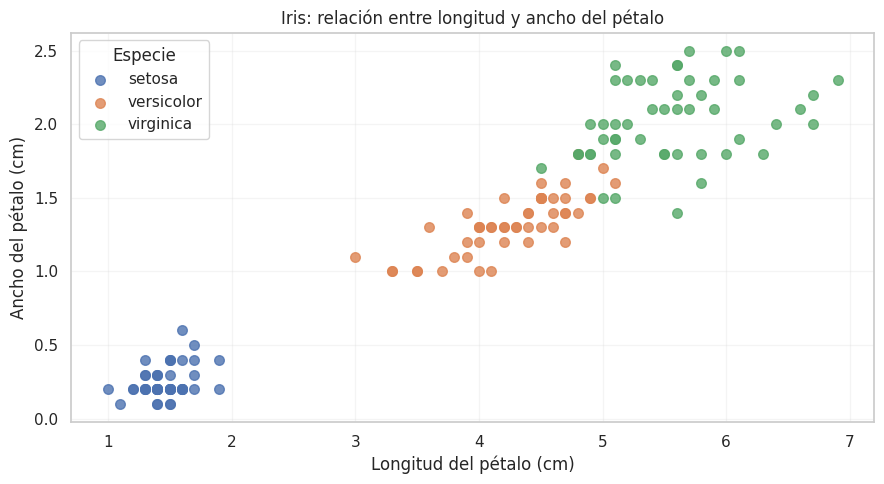

In [4]:
# Creamos el área del gráfico.
plt.figure(figsize=(9, 5))

# Dibujamos las muestras de cada especie por separado para mostrar la leyenda.
for clase_id, nombre in enumerate(iris.target_names):
    subconjunto = df[df["species_id"] == clase_id]
    plt.scatter(subconjunto["petal length (cm)"],
                subconjunto["petal width (cm)"],
                label=nombre, alpha=0.8, s=48)

# Etiquetamos ambos ejes y el gráfico.
plt.xlabel("Longitud del pétalo (cm)")
plt.ylabel("Ancho del pétalo (cm)")
plt.title("Iris: relación entre longitud y ancho del pétalo")
plt.legend(title="Especie")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## + Feature Engineering

Variables:
- X (entradas): todas las características numéricas (longitud/ancho de sépalo y pétalo).

- y (salida): la clase de la flor (setosa, versicolor y virginica).

- Se divide el dataset en 80% entrenamiento y 20% prueba.

- Se aplica escalado con StandardScaler, para que todas las características estén en una escala similar (muy importante para mantener los datos en un rango pequeño )

## + Preprocesamiento

In [5]:

# X contiene las cuatro características de cada flor.
X = iris.data.astype(float)

# y contiene el número de la especie de cada flor (0, 1 o 2).
Y = iris.target.astype(int)

# Train/Test split (estratificado para mantener proporciones por clase)
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.20, random_state=42, stratify=Y
)

# Escalado (fit en train, transform en train y test)
scaler = StandardScaler()

#Estandarizamos los valores para facilitar el descenso de gradiente.
# Aprender media/desviación solo con entrenamiento y escalarlo.
X_train_scaled = scaler.fit_transform(X_train)

# Transformar prueba usando la media/desviación del entrenamiento.
X_test_scaled  = scaler.transform(X_test)

print("Datos escalados y divididos correctamente:")
print(f"Muestras de entrenamiento: {X_train_scaled.shape[0]}")
print(f"Muestras de prueba: {X_test_scaled.shape[0]}")

Datos escalados y divididos correctamente:
Muestras de entrenamiento: 120
Muestras de prueba: 30


## + Model Selection

##### Para resolver este problema utilizamos un perceptron multicapa porque el objetivo es clasificar flores de tres especies a partir de cuatro características numéricas: largo y ancho del sépalo, y largo y ancho del pétalo. Como conocemos la especie de cada muestra, se trata de un problema de aprendizaje supervisado y clasificación multiclase.
##### MLP es funcional por las siguientes características:
- Procesamiento de múltiples características: analiza simultáneamente las cuatro medidas de cada flor para realizar la clasificación.

- Clasificación multiclase: permite distinguir entre las tres especies presentes en el dataset.

- Aprendizaje mediante entrenamiento: ajusta sus pesos y sesgos para reducir los errores de predicción.




In [29]:
# ReLU conserva los valores positivos y convierte los negativos en cero.
def relu(z):
    return np.maximum(0, z)

# La derivada de ReLU vale 1 si z > 0 y 0 en los demás casos.
def derivada_relu(z):
    return (z > 0).astype(float)

# Softmax convierte las salidas en probabilidades que suman uno por fila.
def softmax(z):
    z_estable = z - np.max(z, axis=1, keepdims=True)  # Evita desbordamiento numérico.
    exp_z = np.exp(z_estable)                          # Calcula las exponenciales.
    return exp_z / np.sum(exp_z, axis=1, keepdims=True)  # Normaliza por muestra.

# La entropía cruzada penaliza cuando la probabilidad de la clase correcta es baja.
def entropia_cruzada(probabilidades, etiquetas):
    m = len(etiquetas)                                  # Número de muestras.
    prob_correctas = probabilidades[np.arange(m), etiquetas]  # Clase verdadera.
    return -np.mean(np.log(np.clip(prob_correctas, 1e-12, 1.0)))  # Evita log(0).

In [30]:
# Implementamos manualmente el funcionamiento y aprendizaje de una red neuronal MLP.
class MLPDesdeCero:
    def __init__(self, n_entradas=4, n_ocultas=10, n_salidas=3, tasa=0.05, semilla=42):
        rng = np.random.default_rng(semilla)  # Generador reproducible.
        self.tasa = tasa                       # Tamaño del paso del descenso de gradiente.

        # Inicialización He: adecuada para una capa oculta con ReLU.
        self.W1 = rng.normal(0, np.sqrt(2 / n_entradas), (n_entradas, n_ocultas))
        self.b1 = np.zeros((1, n_ocultas))     # Sesgos de la capa oculta.
        self.W2 = rng.normal(0, np.sqrt(2 / n_ocultas), (n_ocultas, n_salidas))
        self.b2 = np.zeros((1, n_salidas))     # Sesgos de la capa de salida.
        self.historial_perdida = []           # Conservamos el error de cada época.

    # Propagación hacia adelante: de las características a las probabilidades.
    def forward(self, X):
        Z1 = X @ self.W1 + self.b1            # Combinación lineal de la capa oculta.
        A1 = relu(Z1)                        # Activación no lineal ReLU.
        Z2 = A1 @ self.W2 + self.b2           # Combinación lineal de salida.
        A2 = softmax(Z2)                     # Probabilidades para las tres especies.
        return Z1, A1, A2                    # Variables necesarias para backpropagation.

    # Ajusta pesos y sesgos calculando manualmente los gradientes.
    def entrenar(self, X, y, epocas=2500):
        m = X.shape[0]                       # Número de flores de entrenamiento.
        self.historial_perdida = []          # Reiniciamos el historial.

        for epoca in range(epocas):
            Z1, A1, A2 = self.forward(X)     # Primera fase: forward propagation.
            perdida = entropia_cruzada(A2, y)  # Error actual del modelo.
            self.historial_perdida.append(perdida)

            # Derivada de softmax + entropía cruzada respecto a Z2.
            dZ2 = A2.copy()                  # Copiamos probabilidades para no alterarlas.
            dZ2[np.arange(m), y] -= 1       # Restamos las etiquetas one-hot implícitas.
            dZ2 /= m                        # Promediamos sobre las muestras.

            # Gradientes de los pesos y sesgos de la capa de salida.
            dW2 = A1.T @ dZ2
            db2 = np.sum(dZ2, axis=0, keepdims=True)

            # Propagamos el gradiente hacia la capa oculta (regla de la cadena).
            dZ1 = (dZ2 @ self.W2.T) * derivada_relu(Z1)
            dW1 = X.T @ dZ1                  # Gradientes de los pesos de entrada.
            db1 = np.sum(dZ1, axis=0, keepdims=True)  # Gradientes de sesgos ocultos.

            # Actualizamos pesos y sesgos con descenso de gradiente.
            self.W1 -= self.tasa * dW1
            self.b1 -= self.tasa * db1
            self.W2 -= self.tasa * dW2
            self.b2 -= self.tasa * db2

            # Informamos el avance ocasionalmente para no saturar la salida.
            if (epoca + 1) % 500 == 0 or epoca == 0:
                print(f"Época {epoca + 1:4d}/{epocas} | pérdida = {perdida:.5f}")

    # Obtenemos la probabilidad predicha para cada una de las tres clases.
    def predecir_probabilidades(self, X):
        return self.forward(X)[2]

    # Escogemos la especie que tiene la mayor probabilidad.
    def predecir(self, X):
        return np.argmax(self.predecir_probabilidades(X), axis=1)

In [66]:
# Construimos la red con cuatro entradas, diez neuronas ocultas y tres salidas.
modelo = MLPDesdeCero(n_entradas=4, n_ocultas=10, n_salidas=3,
                      tasa=0.05, semilla=42)

# Verificamos las dimensiones esperadas de las matrices de pesos.
print("W1 (entrada → oculta):", modelo.W1.shape)
print("b1 (oculta):", modelo.b1.shape)
print("W2 (oculta → salida):", modelo.W2.shape)
print("b2 (salida):", modelo.b2.shape)
assert modelo.W1.shape == (4, 10) and modelo.W2.shape == (10, 3)

W1 (entrada → oculta): (4, 10)
b1 (oculta): (1, 10)
W2 (oculta → salida): (10, 3)
b2 (salida): (1, 3)


## + Model Training

La red ajusta sus pesos y sesgos con 3000 épocas, utilizando los datos de entrenamiento escalados.

In [67]:
# Entrenamos la red únicamente con datos de entrenamiento ya escalados.
modelo.entrenar(X_train_scaled, Y_train, epocas=3000)

# Comprobamos que el valor final de pérdida es finito.
print("Pérdida inicial:", round(modelo.historial_perdida[0], 5))
print("Pérdida final:  ", round(modelo.historial_perdida[-1], 5))
assert np.isfinite(modelo.historial_perdida[-1])

Época    1/3000 | pérdida = 1.61089
Época  500/3000 | pérdida = 0.11282
Época 1000/3000 | pérdida = 0.06768
Época 1500/3000 | pérdida = 0.05430
Época 2000/3000 | pérdida = 0.04734
Época 2500/3000 | pérdida = 0.04326
Época 3000/3000 | pérdida = 0.04054
Pérdida inicial: 1.61089
Pérdida final:   0.04054


## + Prediction

El modelo utiliza predecir() para devolver la especie predicha de las 30 flores de prueba. Se comparan las primeras diez predicciones con sus etiquetas verdaderas.

In [68]:
# Generamos predicciones para flores nunca utilizadas para entrenar.
y_pred = modelo.predecir(X_test_scaled)

# Calculamos el porcentaje de predicciones acertadas.
exactitud = accuracy_score(Y_test, y_pred)
aciertos = int(np.sum(Y_test == y_pred))
print(f"Accuracy de prueba: {exactitud:.4f} ({exactitud*100:.2f} %)")
print(f"Aciertos: {aciertos} de {len(Y_test)}")

# Construimos una tabla con las etiquetas reales y las predicciones.
comparacion = pd.DataFrame({
    "Especie real": iris.target_names[Y_test],
    "Especie predicha": iris.target_names[y_pred],
    "¿Correcta?": Y_test == y_pred
})
display(comparacion.head(30))

Accuracy de prueba: 0.9667 (96.67 %)
Aciertos: 29 de 30


,Especie real,Especie predicha,¿Correcta?
0,setosa,setosa,True
1,virginica,virginica,True
2,versicolor,versicolor,True
3,versicolor,versicolor,True
4,setosa,setosa,True
5,versicolor,versicolor,True
6,setosa,setosa,True
7,setosa,setosa,True
8,virginica,virginica,True
9,versicolor,versicolor,True


El modelo aprendio y las clasificó correctamente 29 de las 30 muestras de prueba

## + Model Evaluation

- Accuracy (exactitud): proporción global de predicciones correctas.
$$\mathrm{Accuracy}=\frac{\text{Número de predicciones correctas}}{\text{Número total de predicciones}}$$

- Matriz de confusión: la diagonal principal representa los elementos correctamente clasificados mientras los demas recuadros representan falsos posivos y falsos negativos .

- Precision, recall y F1-score: aportan información adicional sobre el rendimiento en cada especie.



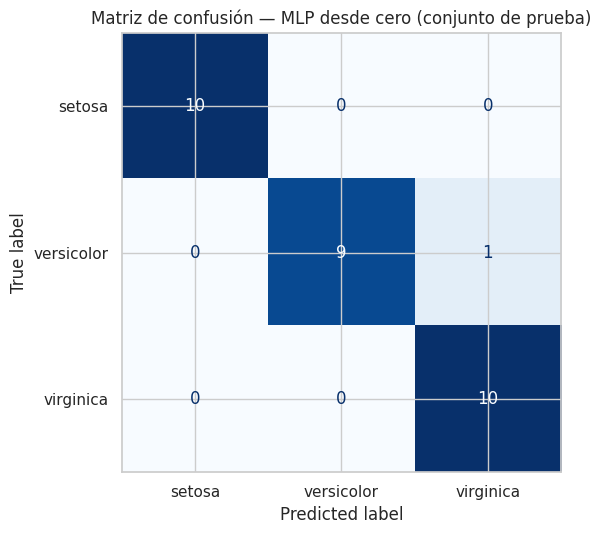

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



In [57]:
# Obtenemos la matriz de confusión con el mismo orden de clases para filas y columnas.
matriz = confusion_matrix(Y_test, y_pred, labels=[0, 1, 2])

# Representamos la matriz con nombres de especies.
fig, ax = plt.subplots(figsize=(7.5, 5.5))
ConfusionMatrixDisplay(confusion_matrix=matriz,
                       display_labels=iris.target_names).plot(
    ax=ax, cmap="Blues", values_format="d", colorbar=False
)
plt.title("Matriz de confusión — MLP desde cero (conjunto de prueba)")
plt.tight_layout()
plt.show()

# Incluimos métricas opcionales útiles para comprender los errores por clase.
print(classification_report(Y_test, y_pred, target_names=iris.target_names,
                            zero_division=0))

# Verificamos que la matriz contabiliza exactamente las muestras de prueba.
assert matriz.sum() == len(Y_test)

La matriz de confusión muestra cuántas veces el modelo acertó o se equivocó por clase. El accuracy indica el porcentaje total de aciertos.

- Diagonal = aciertos; fuera de la diagonal = confusiones entre clases.
- Si la diagonal de la matriz tiene números altos y fuera de la diagonal son bajos, el modelo acierta con alta frecuencia.
- Accuracy cercano a 1.00 sugiere muy buen desempeño global en la clasificación.
- En el reporte, valores altos de precision/recall/F1 para cada clase indican que el modelo casi no confunde las especies.

## Referencias

- Leonel J. (2018, 29 de octubre). Multilayer Perceptron. Medium. https://medium.com/@jorgesleonel/multilayer-perceptron-6c5db6a8dfa3
- Baladram S. (2024, 25 de octubre). Multilayer Perceptron, Explained: A Visual Guide with Mini 2D Dataset. Medium. https://medium.com/data-science/multilayer-perceptron-explained-a-visual-guide-with-mini-2d-dataset-0ae8100c5d1c
- Kassem (2024, 10 de julio). Building a Multi-Layer Perceptron from Scratch with NumPy. Medium.

